<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/CSET_343_E23CSEU0728_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab Assignment 2: Data Cleaning and Enrichment on a Clinical Dataset
Course: CSET343 AI in Healthcare | Dataset: Heart Failure Clinical Records (UCI)

Objective: perform data cleaning and enrichment on a clinical dataset with missing values.

In [ ]:
import os, sys, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

log = {}   # running log of what each cleaning step changed (used in the final summary)

## Task 1: Dataset Acquisition


In [ ]:
FILE = "heart_failure_clinical_records_dataset.csv"
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv"

def acquire():
    if os.path.exists(FILE):
        return "existing local file"
    try:
        urllib.request.urlretrieve(UCI_URL, FILE)
        return "direct download from UCI"
    except Exception as e:
        print("Direct download failed:", e)
    try:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
        from ucimlrepo import fetch_ucirepo
        hf = fetch_ucirepo(id=519)
        pd.concat([hf.data.features, hf.data.targets], axis=1).to_csv(FILE, index=False)
        return "ucimlrepo package"
    except Exception as e:
        print("ucimlrepo failed:", e)
    from google.colab import files          # last resort: upload the CSV manually
    uploaded = files.upload()
    os.rename(list(uploaded.keys())[0], FILE)
    return "manual upload"

print("Dataset obtained via:", acquire())

Dataset obtained via: direct download from UCI


## Task 2: Load Dataset


In [ ]:
df_orig = pd.read_csv(FILE)
df_orig.columns = [c.strip() for c in df_orig.columns]
if "death_event" in df_orig.columns:                      # ucimlrepo uses lowercase
    df_orig = df_orig.rename(columns={"death_event": "DEATH_EVENT"})

print("Original dataset shape:", df_orig.shape)
print("Missing values in the ORIGINAL file:", int(df_orig.isnull().sum().sum()))
df_orig.head()

Original dataset shape: (299, 13)
Missing values in the ORIGINAL file: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### Task 2b: Create the "dirty" working copy
Because the original has no missing values, we simulate typical clinical-data problems (fixed seed = reproducible):

| Problem | Where | How much |
|---|---|---|
| Missing numeric values | `serum_creatinine`, `ejection_fraction`, `platelets`, `serum_sodium` | 8%, 6%, 5%, 4% of rows |
| Missing categorical values | `smoking`, `sex` | 10%, 3% of rows |
| Invalid entries | `age` | 3 rows with a negative sign (data-entry error) |

`sex` and `smoking` are also converted from 0/1 codes to text labels so they behave as true categorical features.

In [ ]:
rng = np.random.default_rng(42)
df = df_orig.copy()

# 1) make sex / smoking genuine categorical (text) features
df["sex"] = df["sex"].map({1: "Male", 0: "Female"})
df["smoking"] = df["smoking"].map({1: "Smoker", 0: "Non-smoker"})

# 2) inject random missing values
missing_plan = {"serum_creatinine": 0.08, "ejection_fraction": 0.06, "platelets": 0.05,
                "serum_sodium": 0.04, "smoking": 0.10, "sex": 0.03}
for col, frac in missing_plan.items():
    idx = rng.choice(df.index, size=int(round(frac * len(df))), replace=False)
    df.loc[idx, col] = np.nan

# 3) inject invalid entries: negative ages (sign-flip typing error)
bad_idx = rng.choice(df.index, size=3, replace=False)
df.loc[bad_idx, "age"] = -df.loc[bad_idx, "age"]

df_before = df.copy()          # snapshot of the dirty data for the "before" statistics later
log["rows_start"] = len(df)
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20.0,1,265000.00,1.9,130.0,Male,Non-smoker,4,1
1,55.0,0,7861,0,38.0,0,263358.03,1.1,136.0,Male,Non-smoker,6,1
2,65.0,0,146,0,20.0,0,162000.00,1.3,129.0,Male,Smoker,7,1
3,50.0,1,111,0,20.0,0,210000.00,1.9,137.0,Male,Non-smoker,7,1
4,65.0,1,160,1,20.0,0,327000.00,2.7,116.0,Female,Non-smoker,8,1


## Task 3: Summarize Dataset
Number of rows and columns, data types and missing values.

In [ ]:
print(f"Rows: {df.shape[0]}   |   Columns: {df.shape[1]}\n")

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print("Total missing cells:", int(df.isnull().sum().sum()))
summary

Rows: 299   |   Columns: 13

Total missing cells: 108


,dtype,missing,missing_%,unique_values
age,float64,0,0.00,50
anaemia,int64,0,0.00,2
creatinine_phosphokinase,int64,0,0.00,208
diabetes,int64,0,0.00,2
ejection_fraction,float64,18,6.02,16
high_blood_pressure,int64,0,0.00,2
platelets,float64,15,5.02,166
serum_creatinine,float64,24,8.03,37
serum_sodium,float64,12,4.01,26
sex,object,9,3.01,2


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,299.0,59.72,16.63,-77.0,50.5,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,281.0,37.86,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,284.0,263298.21,98653.73,25100.0,211750.0,262000.0,302500.0,850000.0
serum_creatinine,275.0,1.39,1.04,0.5,0.9,1.1,1.4,9.4
serum_sodium,287.0,136.69,4.19,116.0,134.0,137.0,140.0,148.0
time,299.0,130.26,77.61,4.0,73.0,115.0,203.0,285.0


## Task 4: Visualize Missing Values
Seaborn heatmap: each coloured line is a missing cell.

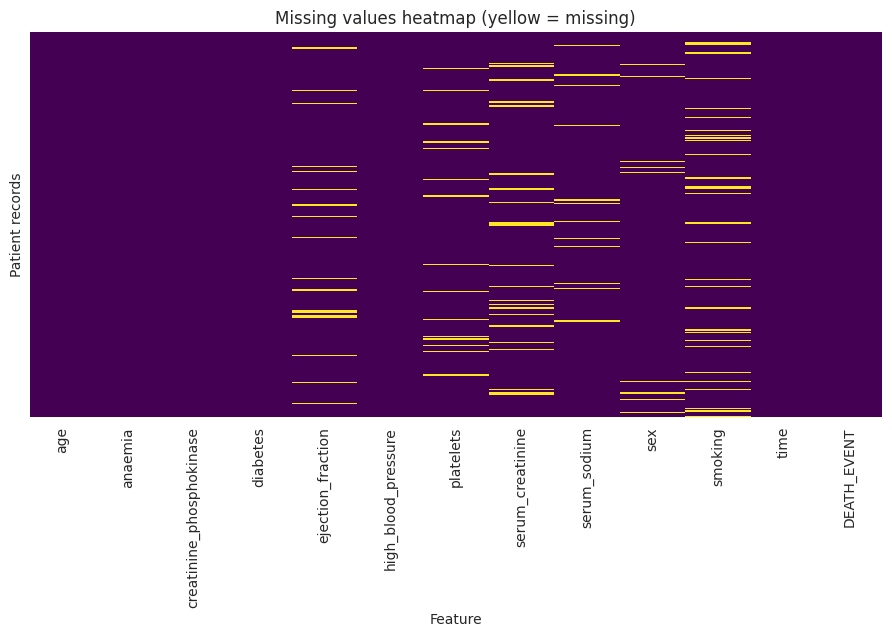

In [ ]:
plt.figure(figsize=(11, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values heatmap (yellow = missing)")
plt.xlabel("Feature"); plt.ylabel("Patient records")
plt.show()

## Task 5: Plot Distributions


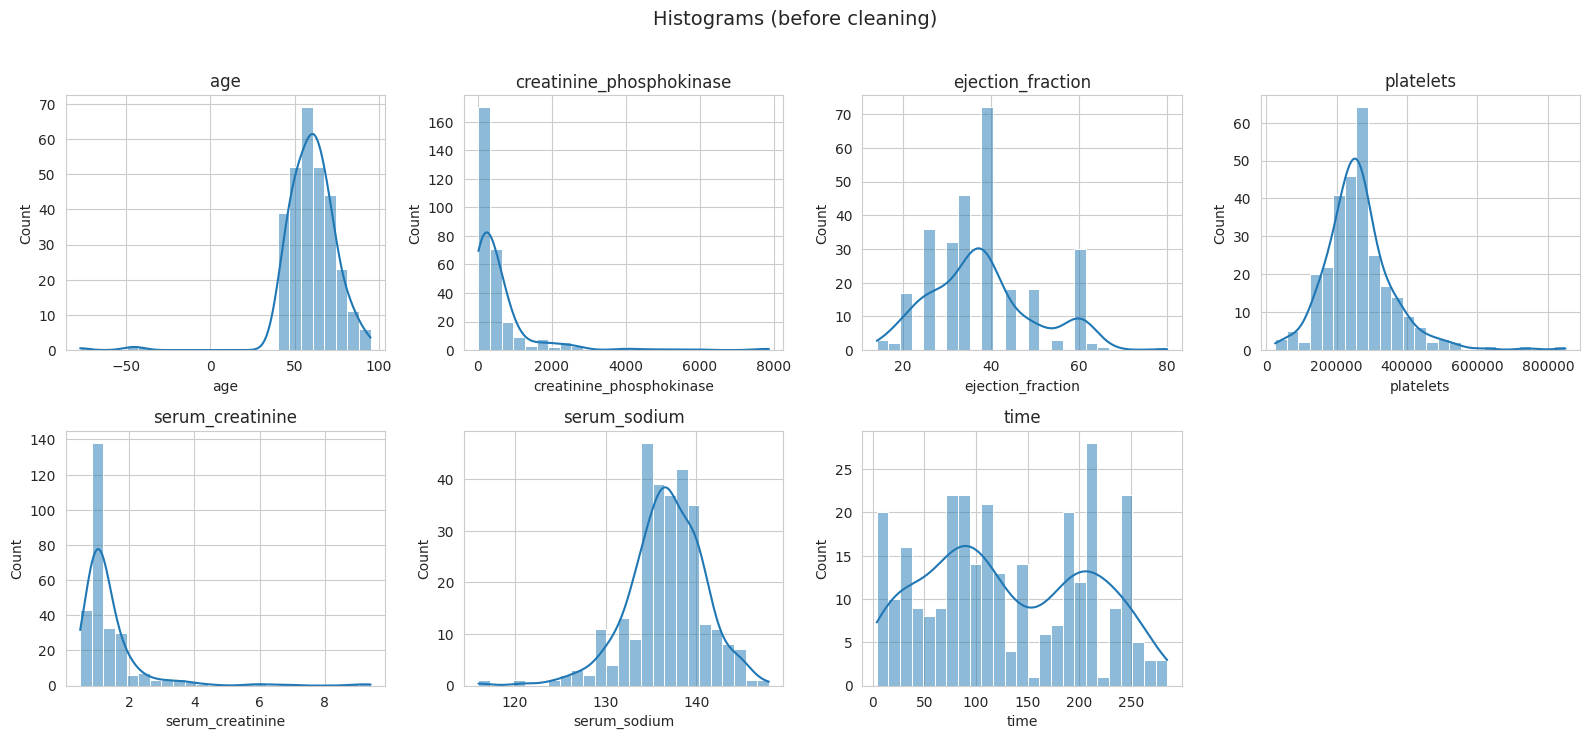

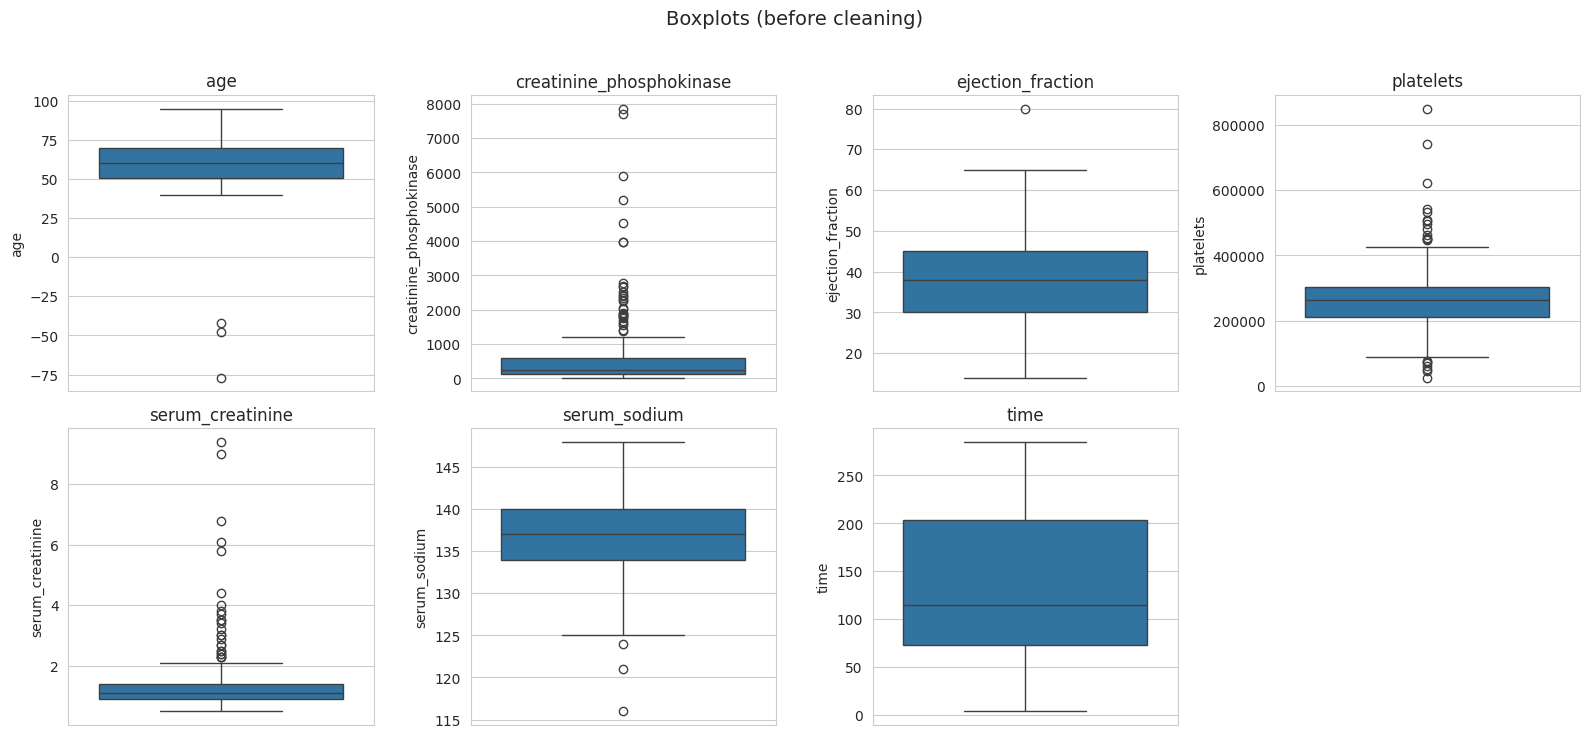

In [ ]:
numerical_cols = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets",
                  "serum_creatinine", "serum_sodium", "time"]
binary_cols = ["anaemia", "diabetes", "high_blood_pressure"]
categorical_cols = ["sex", "smoking"]

def grid_plot(data, cols, kind, title):
    n = len(cols); ncols = 4; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == "hist":
            sns.histplot(data[c].dropna(), bins=25, kde=True, ax=ax)
        else:
            sns.boxplot(y=data[c], ax=ax)
        ax.set_title(c)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout(); plt.show()

grid_plot(df, numerical_cols, "hist", "Histograms (before cleaning)")
grid_plot(df, numerical_cols, "box", "Boxplots (before cleaning)")

## Task 6: Impute Missing Values
- **Numerical features -> median.** `serum_creatinine`, `platelets` and others are right-skewed with outliers, so the median is
  more robust than the mean.
- **`smoking` -> "Unknown".** Smoking status is sensitive and often undisclosed, so we keep "Unknown" as its own
  category instead of guessing.
- **`sex` -> mode.** Only a few values are missing and a separate "Unknown" sex category would not be clinically meaningful.

In [ ]:
missing_before = int(df.isnull().sum().sum())

# numerical -> median
for col in numerical_cols:
    n = int(df[col].isnull().sum())
    if n:
        med = df[col].median()
        df[col] = df[col].fillna(med)
        print(f"{col:28s} {n:3d} missing -> filled with median = {med:.3f}")

# categorical
n_smoke = int(df["smoking"].isnull().sum())
df["smoking"] = df["smoking"].fillna("Unknown")
print(f"{'smoking':28s} {n_smoke:3d} missing -> filled with 'Unknown'")

n_sex = int(df["sex"].isnull().sum())
mode_sex = df["sex"].mode()[0]
df["sex"] = df["sex"].fillna(mode_sex)
print(f"{'sex':28s} {n_sex:3d} missing -> filled with mode = '{mode_sex}'")

log["missing_imputed"] = missing_before
print("\nMissing values remaining:", int(df.isnull().sum().sum()))

ejection_fraction             18 missing -> filled with median = 38.000
platelets                     15 missing -> filled with median = 262000.000
serum_creatinine              24 missing -> filled with median = 1.100
serum_sodium                  12 missing -> filled with median = 137.000
smoking                       30 missing -> filled with 'Unknown'
sex                            9 missing -> filled with mode = 'Male'

Missing values remaining: 0


## Task 7: Remove Outliers (IQR method)


In [ ]:
IQR_K = 1.5
outlier_cols = ["creatinine_phosphokinase", "serum_creatinine", "platelets", "serum_sodium"]

Q1 = df[outlier_cols].quantile(0.25)
Q3 = df[outlier_cols].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - IQR_K * IQR, Q3 + IQR_K * IQR

is_outlier = (df[outlier_cols] < lower) | (df[outlier_cols] > upper)

print("Outliers detected per column:")
print(pd.DataFrame({"lower_fence": lower.round(2), "upper_fence": upper.round(2),
                    "n_outliers": is_outlier.sum()}))

rows_before = len(df)
df = df[~is_outlier.any(axis=1)].reset_index(drop=True)
log["outlier_rows_removed"] = rows_before - len(df)
print(f"\nRows before: {rows_before} | after: {len(df)} | removed: {rows_before - len(df)}")

Outliers detected per column:
                          lower_fence  upper_fence  n_outliers
creatinine_phosphokinase      -581.75      1280.25          29
serum_creatinine                 0.47         1.88          36
platelets                    92500.00    420500.00          24
serum_sodium                   125.75       147.75           5

Rows before: 299 | after: 218 | removed: 81


## Task 8: Correct Inconsistencies


In [ ]:
valid_ranges = {
    "age": (0, 120),
    "creatinine_phosphokinase": (0, 100000),
    "ejection_fraction": (0, 100),
    "platelets": (0, 1_000_000),
    "serum_creatinine": (0, 20),
    "serum_sodium": (100, 180),
    "time": (0, 400),
}

def check_ranges(data):
    rows = []
    for col, (lo, hi) in valid_ranges.items():
        bad = ((data[col] < lo) | (data[col] > hi)).sum()
        rows.append({"feature": col, "valid_range": f"{lo} to {hi}", "invalid_entries": int(bad)})
    return pd.DataFrame(rows)

print("BEFORE fixing:")
display(check_ranges(df))

# fix: negative age -> absolute value (sign-flip typing error)
neg_age = df["age"] < 0
log["invalid_ages_fixed"] = int(neg_age.sum())
df.loc[neg_age, "age"] = df.loc[neg_age, "age"].abs()

print("AFTER fixing:")
display(check_ranges(df))

# other consistency checks
print("Duplicate rows:", int(df.duplicated().sum()))
for col in binary_cols + ["DEATH_EVENT"]:
    assert set(df[col].unique()) <= {0, 1}, f"{col} has non 0/1 values"
assert set(df["sex"].unique()) <= {"Male", "Female"}
assert set(df["smoking"].unique()) <= {"Smoker", "Non-smoker", "Unknown"}
print("Binary and categorical columns contain only valid values.")

BEFORE fixing:


,feature,valid_range,invalid_entries
0,age,0 to 120,3
1,creatinine_phosphokinase,0 to 100000,0
2,ejection_fraction,0 to 100,0
3,platelets,0 to 1000000,0
4,serum_creatinine,0 to 20,0
5,serum_sodium,100 to 180,0
6,time,0 to 400,0


AFTER fixing:


,feature,valid_range,invalid_entries
0,age,0 to 120,0
1,creatinine_phosphokinase,0 to 100000,0
2,ejection_fraction,0 to 100,0
3,platelets,0 to 1000000,0
4,serum_creatinine,0 to 20,0
5,serum_sodium,100 to 180,0
6,time,0 to 400,0


Duplicate rows: 0
Binary and categorical columns contain only valid values.


## Task 9: Feature Engineering
1. **`age_group`**: `<40`, `40-60`, `>60`. (The real dataset has patients aged 40-95, so the `<40` bin will be empty. It is
   still defined because the assignment asks for it.)
2. **`risk_score`**: a normalized score combining `serum_creatinine` and `ejection_fraction`. Higher creatinine (poor kidney
   function) and **lower** ejection fraction (weaker pumping) both indicate worse heart failure, so we use
   `norm(serum_creatinine) * (1 - norm(ejection_fraction))`, then rescale to 0-1. A plain product of the two would
   wrongly *reward* a high ejection fraction.

,patients,death_rate
age_group,,
<40,NaN,NaN
40-60,114.0,0.184
>60,104.0,0.356


risk_score range: 0.0 to 1.0

Mean risk_score by outcome (1 = died):


,risk_score
DEATH_EVENT,
0,0.253
1,0.405


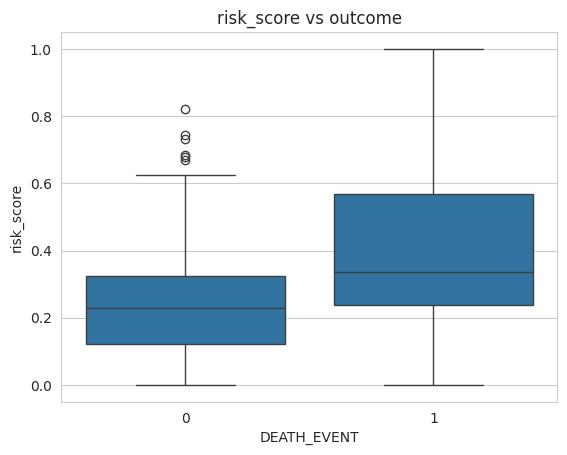

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,age_group,risk_score
0,65.0,0,146,0,20.0,0,162000.00,1.3,129.0,Male,Smoker,7,1,>60,0.569106
1,75.0,1,246,0,15.0,0,127000.00,1.2,137.0,Male,Non-smoker,10,1,>60,0.528455
2,65.0,0,157,0,65.0,0,263358.03,1.5,138.0,Female,Unknown,10,1,>60,0.182927
3,62.0,0,231,0,25.0,1,253000.00,0.9,140.0,Male,Smoker,10,1,>60,0.223577
4,45.0,1,981,0,38.0,0,136000.00,1.1,137.0,Male,Non-smoker,11,1,40-60,0.284553


In [ ]:
# --- age_group
df["age_group"] = np.select([df["age"] < 40, df["age"] <= 60], ["<40", "40-60"], default=">60")

order = ["<40", "40-60", ">60"]
age_summary = (df.groupby("age_group")["DEATH_EVENT"].agg(patients="count", death_rate="mean")
                 .reindex(order))
age_summary["death_rate"] = age_summary["death_rate"].round(3)
display(age_summary)

# --- risk_score
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

raw_risk = minmax(df["serum_creatinine"]) * (1 - minmax(df["ejection_fraction"]))
df["risk_score"] = minmax(raw_risk)

print("risk_score range:", df["risk_score"].min(), "to", df["risk_score"].max())
print("\nMean risk_score by outcome (1 = died):")
display(df.groupby("DEATH_EVENT")["risk_score"].mean().round(3))

sns.boxplot(x="DEATH_EVENT", y="risk_score", data=df)
plt.title("risk_score vs outcome"); plt.show()

df_clean = df.copy()     # cleaned + enriched, human-readable, NOT yet scaled
df_clean.head()

## Task 10: Encode Categorical Variables
- **One-hot encoding** for the nominal features `sex` and `smoking` (no natural order). `smoking` produces three
  columns because it contains the "Unknown" category.
- **Label (ordinal) encoding** for `age_group`, which has a natural order: `<40`=0, `40-60`=1, `>60`=2.
- `anaemia`, `diabetes`, `high_blood_pressure` and `DEATH_EVENT` are already 0/1.

In [ ]:
df_enc = pd.get_dummies(df_clean, columns=["sex", "smoking"], dtype=int)

age_order = {"<40": 0, "40-60": 1, ">60": 2}
df_enc["age_group_encoded"] = df_enc["age_group"].map(age_order)
df_enc = df_enc.drop(columns="age_group")

print("Encoded columns:", list(df_enc.columns))
df_enc.head()

Encoded columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'time', 'DEATH_EVENT', 'risk_score', 'sex_Female', 'sex_Male', 'smoking_Non-smoker', 'smoking_Smoker', 'smoking_Unknown', 'age_group_encoded']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,sex_Female,sex_Male,smoking_Non-smoker,smoking_Smoker,smoking_Unknown,age_group_encoded
0,65.0,0,146,0,20.0,0,162000.00,1.3,129.0,7,1,0.569106,0,1,0,1,0,2
1,75.0,1,246,0,15.0,0,127000.00,1.2,137.0,10,1,0.528455,0,1,1,0,0,2
2,65.0,0,157,0,65.0,0,263358.03,1.5,138.0,10,1,0.182927,1,0,0,0,1,2
3,62.0,0,231,0,25.0,1,253000.00,0.9,140.0,10,1,0.223577,0,1,0,1,0,2
4,45.0,1,981,0,38.0,0,136000.00,1.1,137.0,11,1,0.284553,0,1,1,0,0,1


## Task 11: Normalize Features (MinMaxScaler)
Scale the continuous features to the 0-1 range: `x' = (x - min) / (max - min)`.
Binary, one-hot, encoded and target columns are **not** scaled; `risk_score` is already 0-1.

In [ ]:
scale_cols = numerical_cols          # age, CPK, EF, platelets, creatinine, sodium, time
scaler = MinMaxScaler()

df_scaled = df_enc.copy()
df_scaled[scale_cols] = scaler.fit_transform(df_enc[scale_cols])

print("Min / max of scaled columns:")
display(df_scaled[scale_cols].agg(["min", "max"]).T)
df_scaled.head()

Min / max of scaled columns:


,min,max
age,0.0,1.0
creatinine_phosphokinase,0.0,1.0
ejection_fraction,0.0,1.0
platelets,0.0,1.0
serum_creatinine,0.0,1.0
serum_sodium,0.0,1.0
time,0.0,1.0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,sex_Female,sex_Male,smoking_Non-smoker,smoking_Smoker,smoking_Unknown,age_group_encoded
0,0.454545,0,0.098222,0,0.090909,0,0.123288,0.569106,0.157895,0.000000,1,0.569106,0,1,0,1,0,2
1,0.636364,1,0.182896,0,0.015152,0,0.003425,0.487805,0.578947,0.010791,1,0.528455,0,1,1,0,0,2
2,0.454545,0,0.107536,0,0.772727,0,0.470404,0.731707,0.631579,0.010791,1,0.182927,1,0,0,0,1,2
3,0.400000,0,0.170195,0,0.166667,1,0.434932,0.243902,0.736842,0.010791,1,0.223577,0,1,0,1,0,2
4,0.090909,1,0.805250,0,0.363636,0,0.034247,0.406504,0.578947,0.014388,1,0.284553,0,1,1,0,0,1


## Task 12: Compute Summary Statistics (Before vs After Cleaning)
- **Before:** the dirty data (missing values, negative ages, outliers).
- **After:** the cleaned data in original units (before scaling, so values stay interpretable).

BEFORE cleaning                     AFTER cleaning  \
                                    mean    median       std           mean   
age                                59.72      60.0     16.63          60.49   
creatinine_phosphokinase          581.84     250.0    970.29         337.90   
ejection_fraction                  37.86      38.0     11.83          38.34   
platelets                      263298.21  262000.0  98653.73      253670.46   
serum_creatinine                    1.39       1.1      1.04           1.11   
serum_sodium                      136.69     137.0      4.19         137.02   
time                              130.26     115.0     77.61         134.40   

                                              
                            median       std  
age                           60.0     11.63  
creatinine_phosphokinase     212.5    284.86  
ejection_fraction             38.0     11.72  
platelets                 262000.0  62018.24  
serum_creatinine               1.1      0.28  
serum_sodium                 137.0      3.53  
time                         120.0     74.93

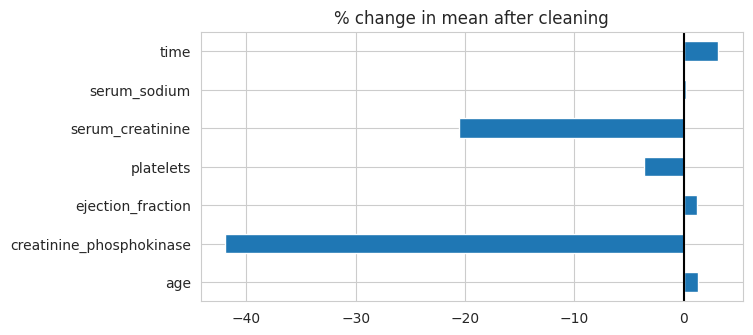

In [ ]:
stats_before = df_before[numerical_cols].agg(["mean", "median", "std"]).T
stats_after = df_clean[numerical_cols].agg(["mean", "median", "std"]).T

comparison = pd.concat([stats_before, stats_after], axis=1, keys=["BEFORE cleaning", "AFTER cleaning"]).round(2)
display(comparison)

# visual comparison of the means (as % change)
pct_change = ((stats_after["mean"] - stats_before["mean"]) / stats_before["mean"] * 100).round(2)
pct_change.plot(kind="barh", figsize=(7, 3.5), title="% change in mean after cleaning")
plt.axvline(0, color="k"); plt.show()

## Task 13: Validate Cleaning
Histograms and boxplots of the cleaned numerical features. There should be no negative ages and much shorter tails.

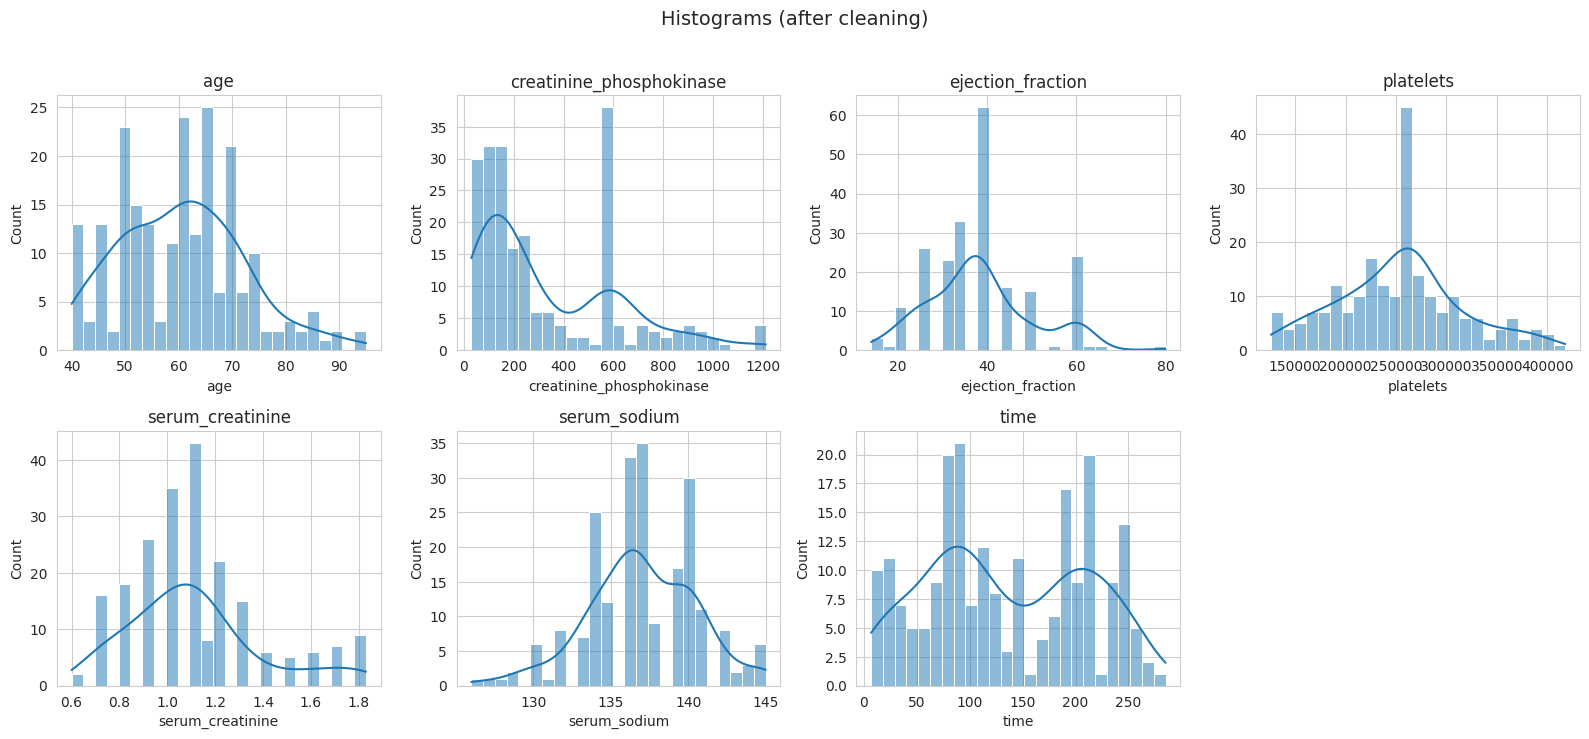

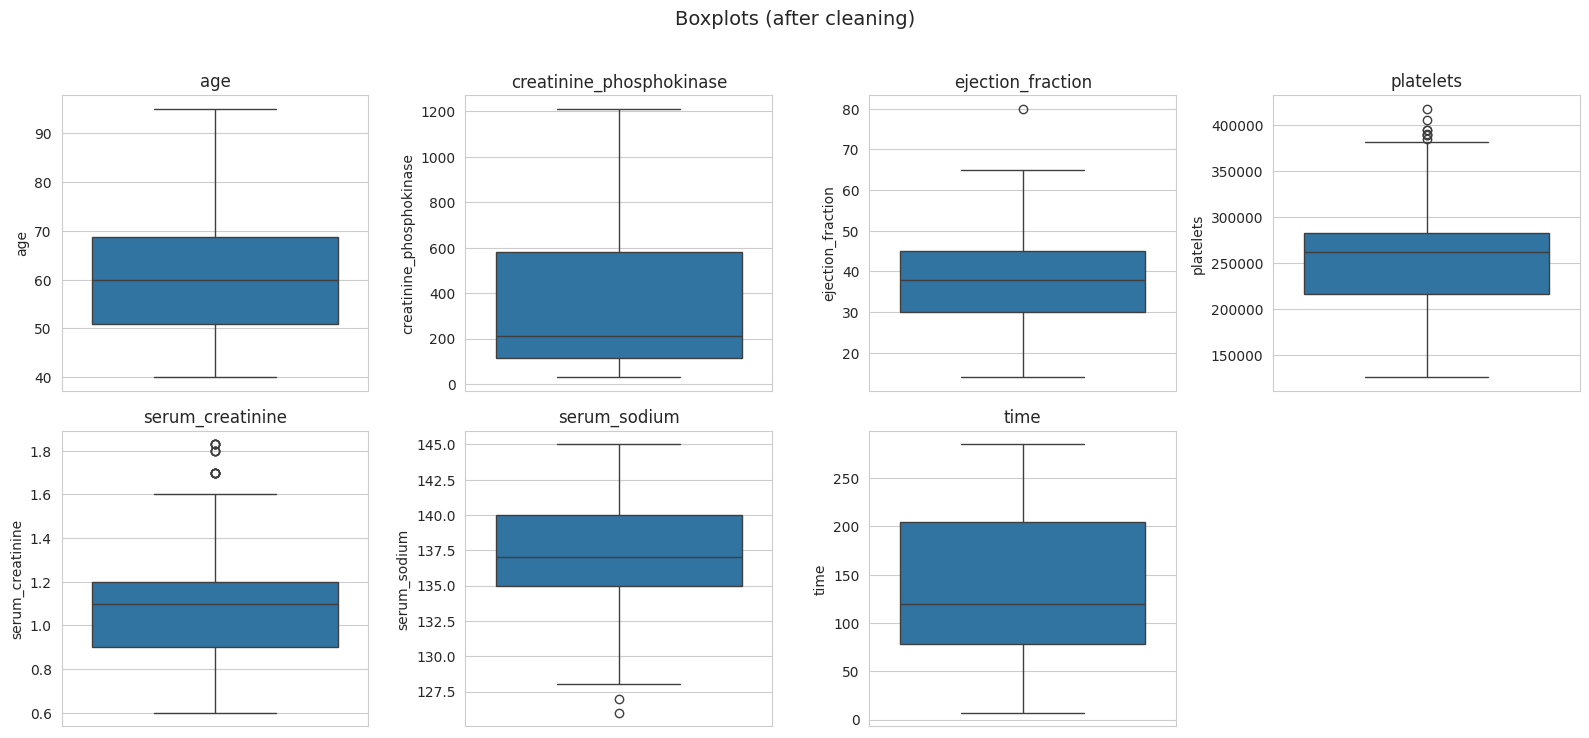

In [ ]:
grid_plot(df_clean, numerical_cols, "hist", "Histograms (after cleaning)")
grid_plot(df_clean, numerical_cols, "box", "Boxplots (after cleaning)")

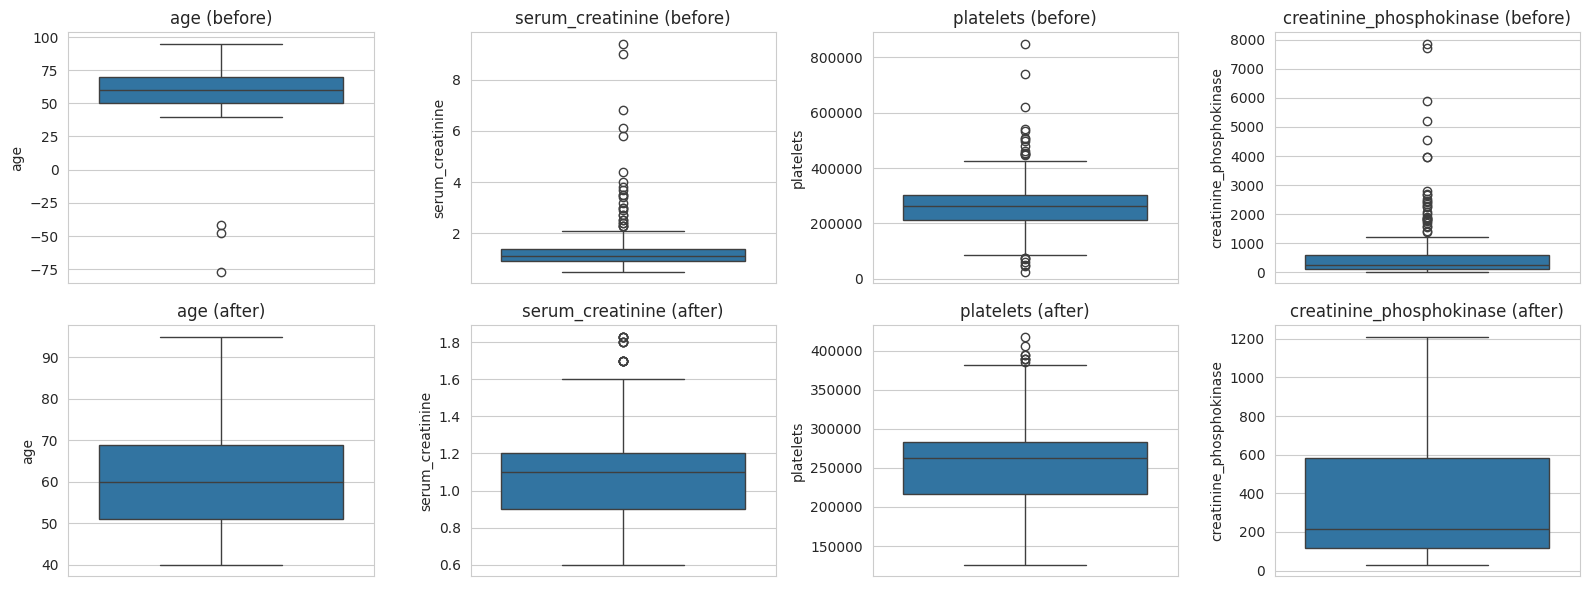

In [ ]:
# side-by-side check on the features that changed the most
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, col in enumerate(["age", "serum_creatinine", "platelets", "creatinine_phosphokinase"]):
    sns.boxplot(y=df_before[col], ax=axes[0, j]); axes[0, j].set_title(f"{col} (before)")
    sns.boxplot(y=df_clean[col], ax=axes[1, j]);  axes[1, j].set_title(f"{col} (after)")
plt.tight_layout(); plt.show()

## Task 14: Check Missing Values
Confirm that no missing values remain in any version of the dataset.

Missing values in cleaned data   : 0
Missing values in encoded data   : 0
Missing values in scaled data    : 0

No missing values remain. 'Unknown' in `smoking` is a deliberate category, not a missing cell.


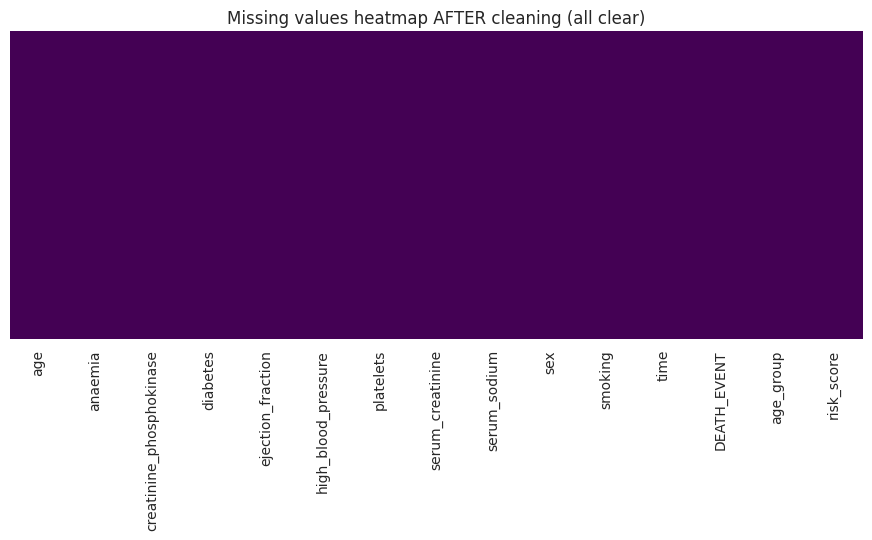

In [ ]:
print("Missing values in cleaned data   :", int(df_clean.isnull().sum().sum()))
print("Missing values in encoded data   :", int(df_enc.isnull().sum().sum()))
print("Missing values in scaled data    :", int(df_scaled.isnull().sum().sum()))
assert df_scaled.isnull().sum().sum() == 0
print("\nNo missing values remain. 'Unknown' in `smoking` is a deliberate category, not a missing cell.")

plt.figure(figsize=(11, 4))
sns.heatmap(df_clean.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values heatmap AFTER cleaning (all clear)")
plt.show()

## Final Cleaning Summary

In [ ]:
final = {
    "Patients at start": log["rows_start"],
    "Missing cells imputed": log["missing_imputed"],
    "Rows removed as outliers (IQR)": log["outlier_rows_removed"],
    "Invalid ages corrected": log["invalid_ages_fixed"],
    "Patients in final dataset": len(df_scaled),
    "Features in final dataset": df_scaled.shape[1],
}
display(pd.Series(final, name="value").to_frame())

df_scaled.to_csv("heart_failure_cleaned_scaled.csv", index=False)
df_clean.to_csv("heart_failure_cleaned_readable.csv", index=False)
print("Saved: heart_failure_cleaned_scaled.csv and heart_failure_cleaned_readable.csv")

try:
    from google.colab import files
    files.download("heart_failure_cleaned_scaled.csv")
except Exception:
    pass

,value
Patients at start,299
Missing cells imputed,108
Rows removed as outliers (IQR),81
Invalid ages corrected,3
Patients in final dataset,218
Features in final dataset,18


Saved: heart_failure_cleaned_scaled.csv and heart_failure_cleaned_readable.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>